In [1]:
# Names

# Amanda Le (al58528)
# Hannah Fan (hlf583)
# Rianna Skaria (rrs3385)
# Prithikaa Sadagopan (ps35493)

# Predicting Sleep Debt Severity from Evening Technology Habits

## Introduction

Sleep debt occurs when an individual does not obtain sufficient
sleep relative to their sleep needs. Understanding the relationship
between evening technology habits and sleep debt may help identify
patterns associated with insufficient sleep.

In this project, we investigate whether sleep debt severity can
be predicted using demographic characteristics, evening phone
habits, and other lifestyle variables.

## Dataset

Our dataset contains 8,500 observations and 17 features describing
individuals' lifestyle habits, technology use, and sleep-related
measurements.

link: https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits

In [2]:
# standard headers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# load data set
sleep = pd.read_csv('bedtime_screentime_sleep_debt.csv')
print(sleep.shape)
display(sleep.head())

(8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [4]:
# check data types and non-null counts
sleep.info()

# count missing values in each column
missingCount = sleep.isna().sum()
print(missingCount)

# print the total number of missing values
print("Total missing values:", sleep.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

### Data Exploration and Analysis

To start, we explored the dataset to understand its structure, identify patterns, and examine relationships between lifestyle habits and sleep debt severity. This included analyzing feature distributions, summary statistics, correlations, and differences across sleep debt categories. 

We also used K-Means clustering to investigate potential groupings in lifestyle behaviors and Isolation Forest to identify anomolies. 

Finally, we performed feature engineering by using bins for selected numerical variables and applying one-hot encoding to prepare the data for the modeling phase.

In [5]:
# check for duplicate rows and duplicate user IDs
print("Duplicate rows:", sleep.duplicated().sum())
print("Unique user IDs:", sleep["user_id"].nunique())

# examine the target distribution
display(sleep["sleep_debt_category"].value_counts())
display(sleep["sleep_debt_category"].value_counts(normalize=True))

Duplicate rows: 0
Unique user IDs: 8500


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

sleep_debt_category
Moderate Debt        0.524941
Mild Deficit         0.235765
Optimal Recovery     0.163176
Severe Sleep Debt    0.076118
Name: proportion, dtype: float64

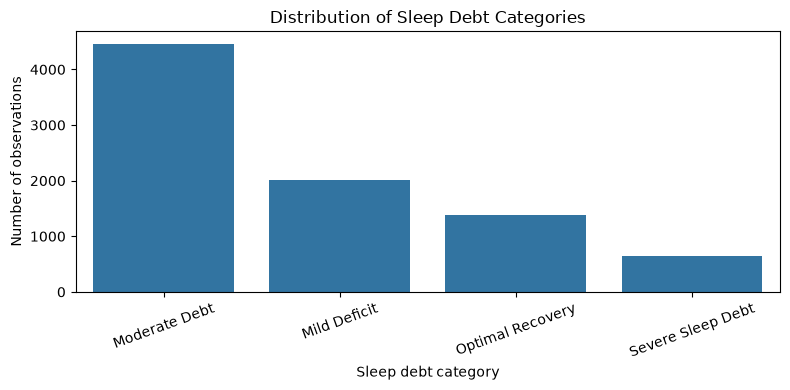

In [6]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=sleep,
    x="sleep_debt_category",
    order=sleep["sleep_debt_category"].value_counts().index
)
plt.title("Distribution of Sleep Debt Categories")
plt.xlabel("Sleep debt category")
plt.ylabel("Number of observations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [7]:
# The chart shows that the target distribution is imbalanced. Moderate Sleep Debt represents about 52.5% of observations, while Severe Sleep Debt represents only 7.6%. This imbalance will be considered when evaluating our classification models.

In [8]:
# compare numeric variables across sleep-debt categories
numeric_to_compare = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "morning_alarm_snoozes",
    "sleep_latency_min",
    "total_sleep_hours",
    "deep_sleep_pct",
    "rem_sleep_pct",
    "next_day_fatigue_score"
]

display(
    sleep.groupby("sleep_debt_category")[numeric_to_compare]
    .agg(["mean", "median"])
    .round(2)
)

age        bedtime_phone_minutes         \
                      mean median                  mean median   
sleep_debt_category                                              
Mild Deficit         34.37   32.0                 45.45   43.0   
Moderate Debt        34.38   32.0                 64.12   60.0   
Optimal Recovery     34.70   32.0                 33.51   30.0   
Severe Sleep Debt    33.45   30.0                123.60  125.0   

                    screen_brightness_pct        caffeine_post_5pm_mg         \
                                     mean median                 mean median   
sleep_debt_category                                                            
Mild Deficit                        55.37   56.0                33.03    0.0   
Moderate Debt                       54.52   55.0                31.56    0.0   
Optimal Recovery                    54.24   55.0                30.24    0.0   
Severe Sleep Debt                   60.80   60.0                51.66   25.0   

                    physical_activity_min         ... sleep_latency_min  \
                                     mean median  ...              mean   
sleep_debt_category                               ...                     
Mild Deficit                        35.27   35.0  ...             34.69   
Moderate Debt                       35.97   36.0  ...             42.37   
Optimal Recovery                    36.11   35.0  ...             28.92   
Severe Sleep Debt                   34.30   32.0  ...             72.70   

                           total_sleep_hours        deep_sleep_pct         \
                    median              mean median           mean median   
sleep_debt_category                                                         
Mild Deficit          33.4              7.23   7.21          22.09   22.3   
Moderate Debt         40.7              5.55   5.66          21.75   21.8   
Optimal Recovery      28.0              8.35   8.23          22.37   22.4   
Severe Sleep Debt     72.9              3.76   3.59          19.18   19.2   

                    rem_sleep_pct        next_day_fatigue_score         
                             mean median                   mean median  
sleep_debt_category                                                     
Mild Deficit                19.16   19.2                   1.83    1.4  
Moderate Debt               19.15   19.2                   4.68    4.6  
Optimal Recovery            19.19   19.2                   1.08    1.0  
Severe Sleep Debt           18.48   18.4                   9.58    9.9  

[4 rows x 22 columns]

In [9]:
# Severe Sleep Debt showed the highest in bedtime phone usage, sleep latency, caffeine intake, alarm snoozes, and next-day fatigue, along with the lowest total sleep duration. Optimal Recovery showed the opposite patterns for most of these variables. Age was relatively consistent across categories, suggesting it may be less useful for distinguishing sleep-debt severity.

Numerical Feature Distributions:

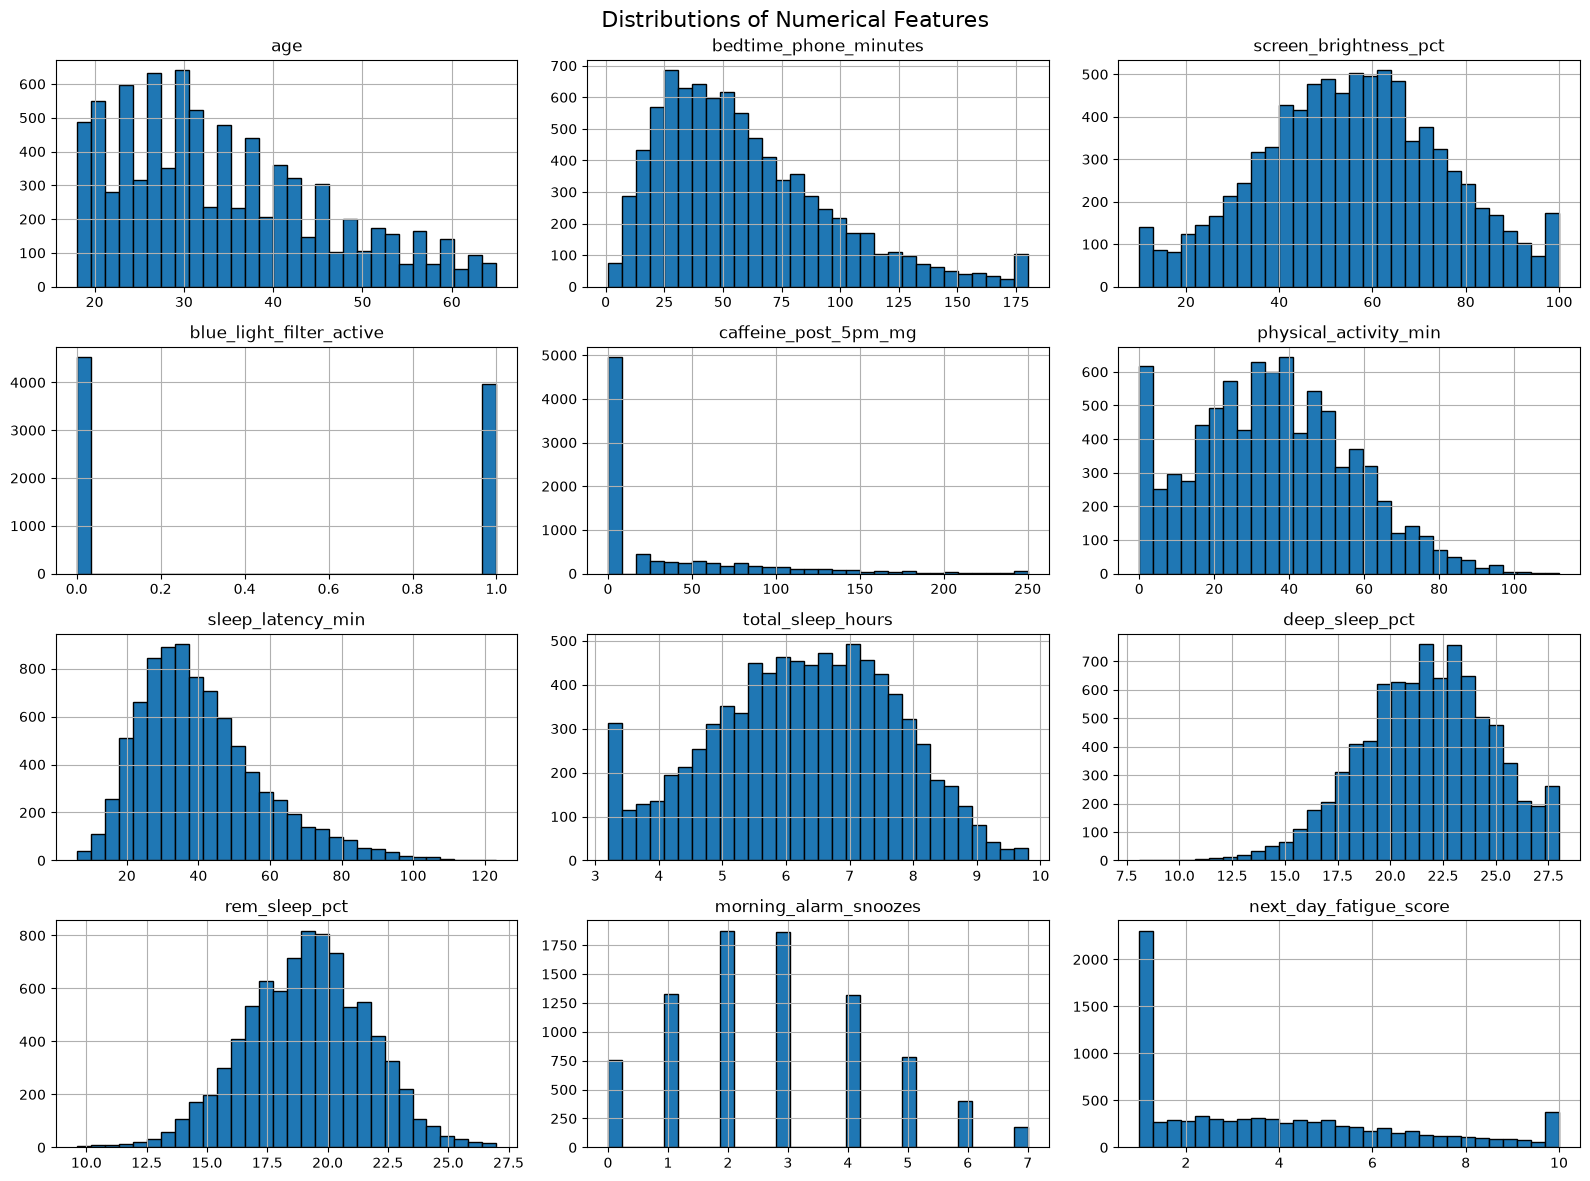

In [10]:
numeric_features = [
    col for col in sleep.select_dtypes(include=np.number).columns
    if col != "user_id"
]

# plot distributions
sleep[numeric_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
# summary statistics and skewness
distribution_summary = sleep[numeric_features].agg(
    ["mean", "median", "std", "min", "max"]
).T

distribution_summary["skewness"] = sleep[numeric_features].skew()

display(distribution_summary.round(2))

,mean,median,std,min,max,skewness
age,34.36,32.00,11.58,18.0,65.0,0.68
bedtime_phone_minutes,59.25,51.00,36.93,1.0,180.0,1.03
screen_brightness_pct,55.15,55.00,19.85,10.0,100.0,-0.01
blue_light_filter_active,0.47,0.00,0.50,0.0,1.0,0.13
caffeine_post_5pm_mg,33.22,0.00,51.94,0.0,250.0,1.78
physical_activity_min,35.70,35.00,20.82,0.0,112.0,0.26
sleep_latency_min,40.67,37.60,17.44,6.0,123.3,0.97
total_sleep_hours,6.27,6.33,1.45,3.2,9.8,-0.16
deep_sleep_pct,21.74,21.90,3.07,8.1,28.0,-0.26
rem_sleep_pct,19.11,19.10,2.55,9.6,27.0,-0.11


In [12]:
# Numerical Feature Distribution Analysis

# The numerical feature distributions revealed several differences in the characteristics of our dataset. Age, bedtime phone usage, evening caffeine consumption, sleep latency, and next-day fatigue were right-skewed, indicating that most observations were concentrated toward lower values. Evening caffeine consumption showed the strongest skewness (1.78), with a median of 0 mg compared to a mean of 33.22 mg.

# Screen brightness, total sleep hours, and REM sleep percentage were approximately normally distributed. Deep sleep percentage showed a slight left skew, while physical activity was relatively symmetric. Blue-light filter usage was binary, and morning alarm snoozes followed a discrete distribution.

# These suggest that certain features may benefit from transformations or binning. Additionally, the differences in numerical scales make standardization important for algorithms that uses distance (K-Means, KNN). The right-skewed features will also be investigated further during anomaly detection.

Exploring relationships between features:

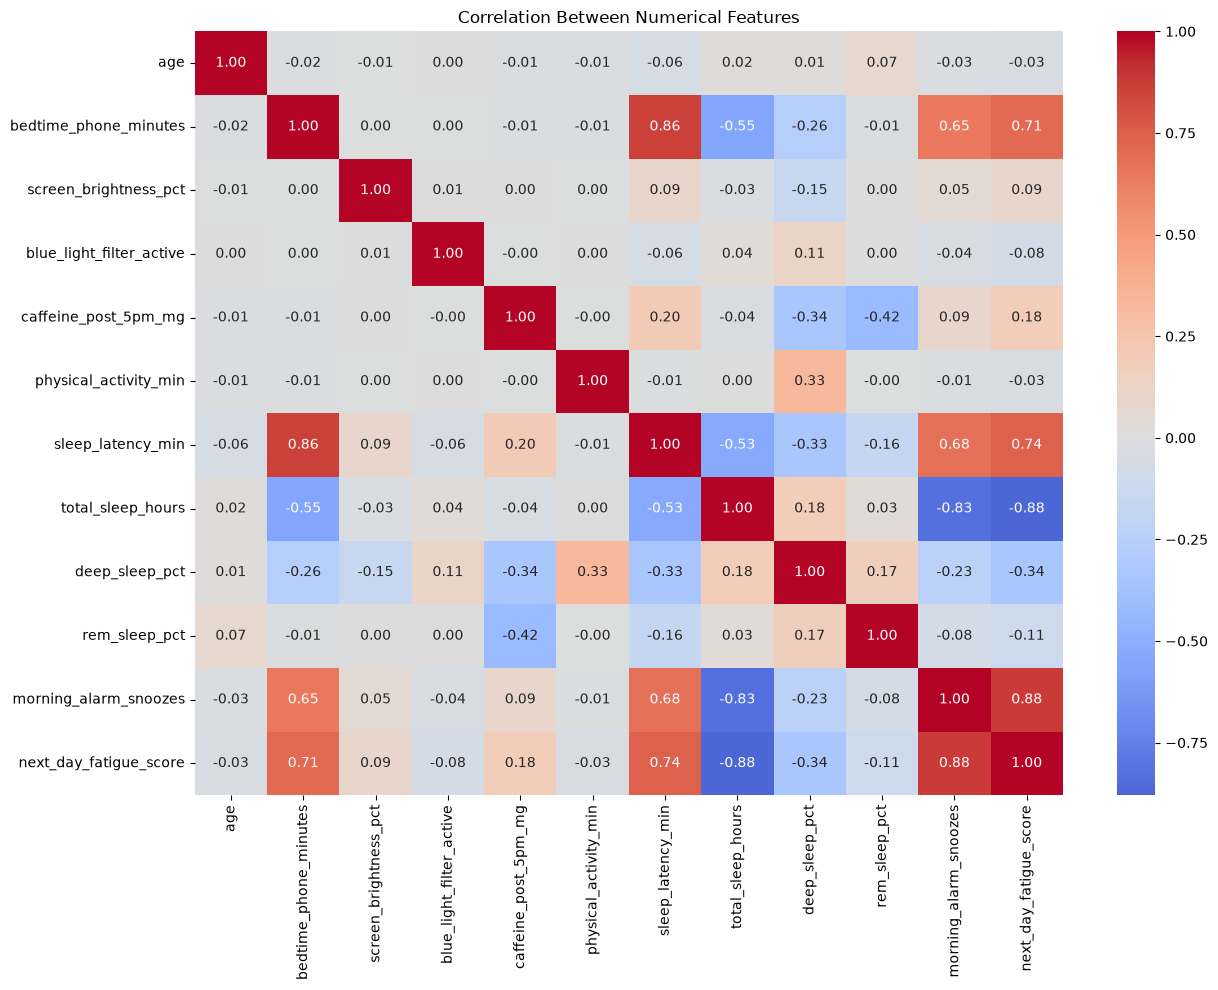

In [13]:
# calculate correlations between numerical features
correlation = sleep[numeric_features].corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [14]:
# The correlation analysis shows a strong positive relationship between bedtime phone usage and sleep latency (0.86), suggesting that people with more bedtime phone usage tend to take longer to fall asleep.
# Total sleep hours had a strong negative relationship with next-day fatigue (-0.88). 
# Evening caffeine had only a weak positive correlation with sleep latency (0.20). 
# These relationships suggest that certain lifestyle and features may provide useful information for understanding sleep patterns.

In [15]:
# compare chronotype with sleep debt category
chronotype_comparison = pd.crosstab(
    sleep["chronotype"],
    sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(chronotype_comparison.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
chronotype,,,,
Intermediate,32.04,50.13,11.98,5.85
Morning Lark,30.67,24.39,42.36,2.59
Night Owl,3.95,81.02,0.20,14.83


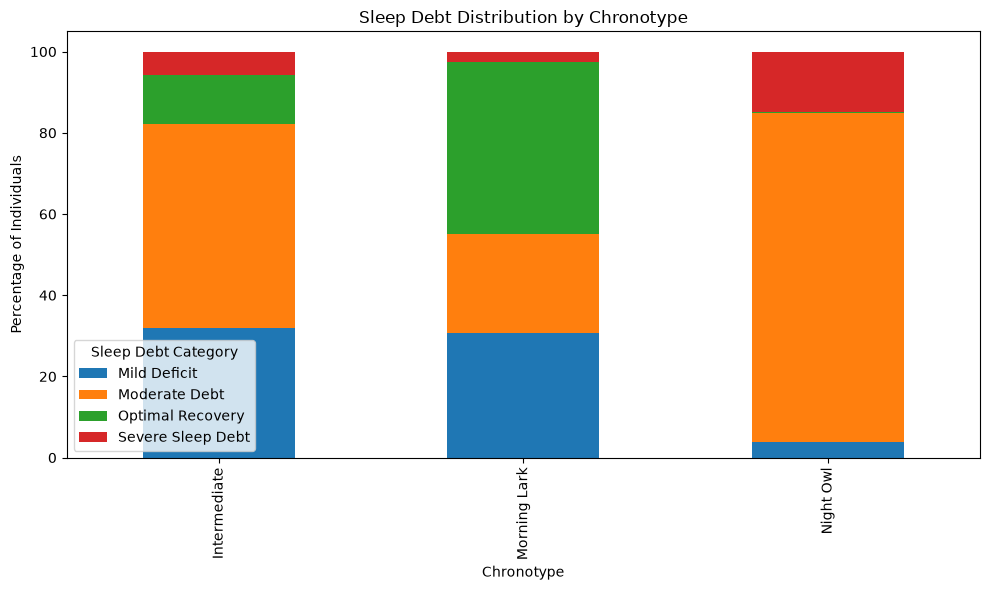

In [16]:
chronotype_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sleep Debt Distribution by Chronotype")
plt.xlabel("Chronotype")
plt.ylabel("Percentage of Individuals")
plt.legend(title="Sleep Debt Category")
plt.tight_layout()
plt.show()

In [17]:
# compare occupation with sleep debt category
occupation_comparison = pd.crosstab(
    sleep["occupation_type"],
    sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(occupation_comparison.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
occupation_type,,,,
Corporate 9-to-5,25.44,49.44,18.68,6.45
Freelance / Creative,25.97,50.94,16.20,6.88
Healthcare / Shift Worker,8.73,71.41,1.60,18.25
Remote Tech,24.88,50.93,18.44,5.74
Student,26.39,49.14,18.50,5.98


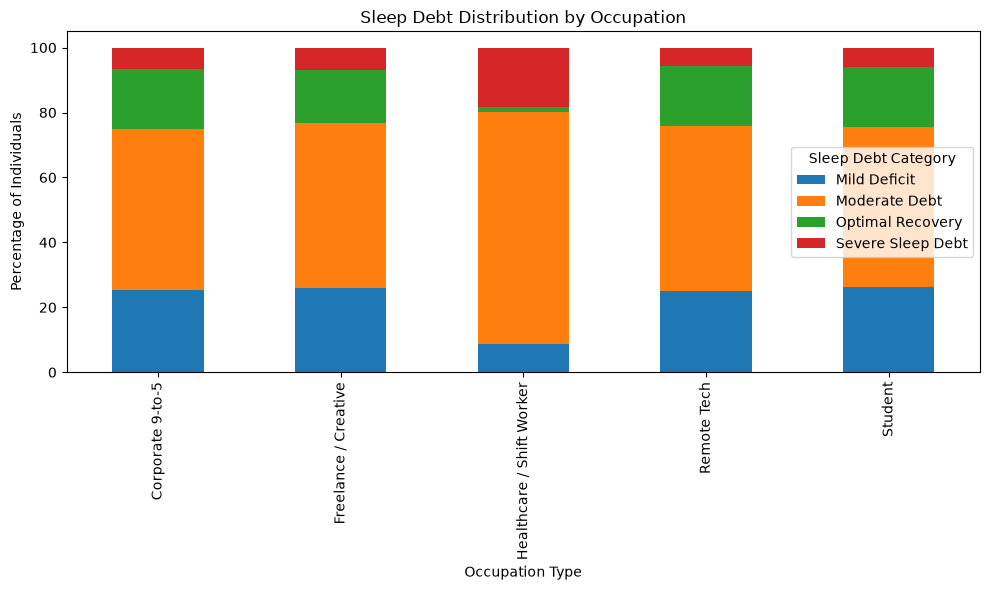

In [18]:
occupation_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sleep Debt Distribution by Occupation")
plt.xlabel("Occupation Type")
plt.ylabel("Percentage of Individuals")
plt.legend(title="Sleep Debt Category")
plt.tight_layout()
plt.show()

In [19]:
# compare bedtime app with sleep debt category
bedtime_app_comparison = pd.crosstab(
    sleep["primary_bedtime_app"],
    sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(bedtime_app_comparison.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
primary_bedtime_app,,,,
Instagram / Reddit,23.50,53.19,15.64,7.67
Messaging / Chat,24.44,51.59,17.36,6.61
News / Reading,26.34,53.52,16.11,4.03
Streaming (Netflix/Hulu),23.98,52.81,17.60,5.61
TikTok / Reels,22.16,51.91,15.10,10.83
YouTube,23.76,52.44,17.01,6.79


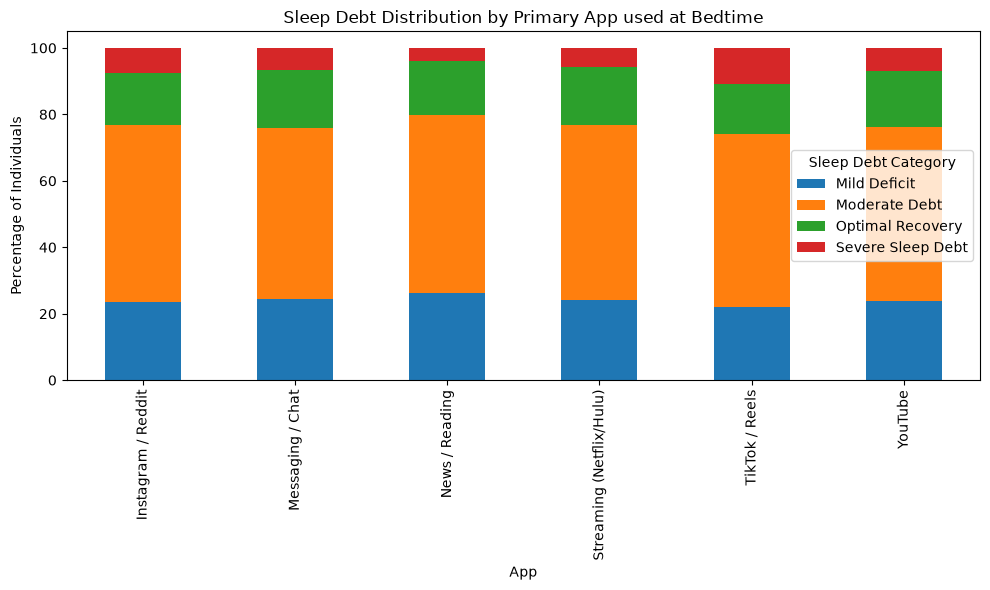

In [20]:
bedtime_app_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sleep Debt Distribution by Primary App used at Bedtime")
plt.xlabel("App")
plt.ylabel("Percentage of Individuals")
plt.legend(title="Sleep Debt Category")
plt.tight_layout()
plt.show()

In [21]:
# Chronotype showed notable differences across sleep-debt categories. Morning Larks had the highest proportion of Optimal Recovery (42.36%), while Night Owls were heavily concentrated in Moderate Debt (81.02%) and had the highest proportion of Severe Sleep Debt (14.83%).

# Occupation type also showed differences, especially for Healthcare / Shift Workers, who had the highest Severe Sleep Debt percentage (18.25%).

# Primary bedtime app showed smaller differences. TikTok / Reels usage had the highest Severe Sleep Debt percentage (10.83%).

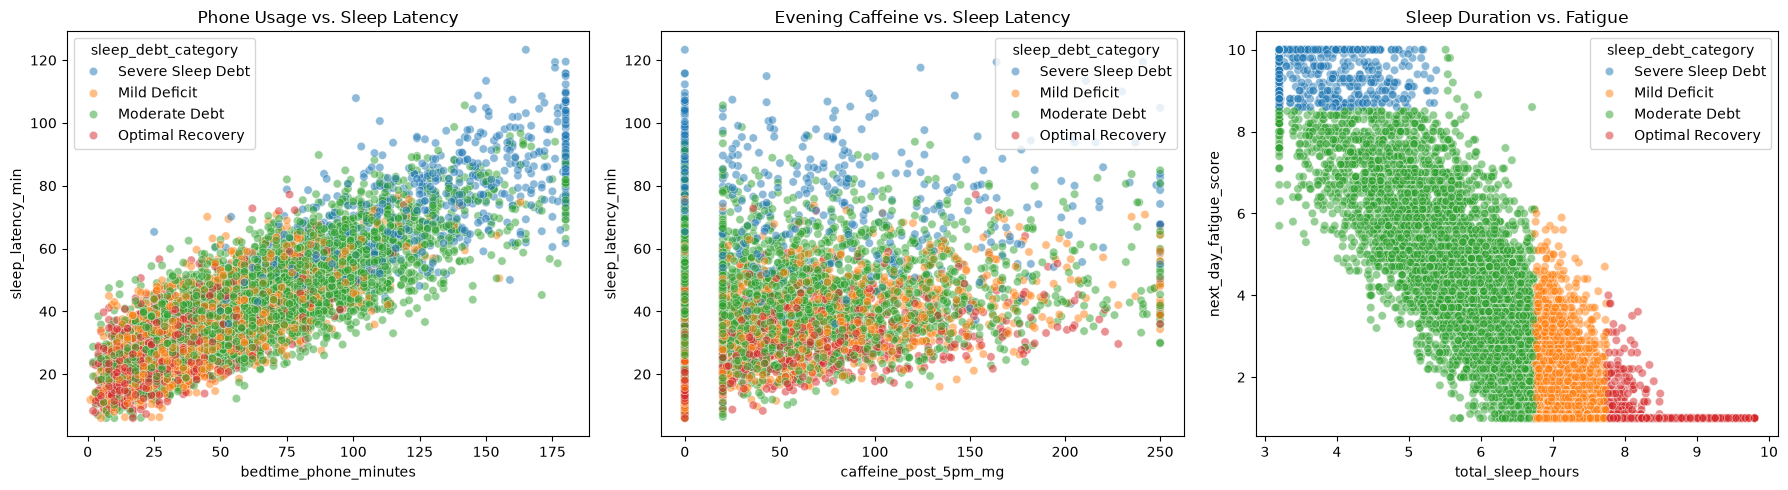

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=sleep,
    x="bedtime_phone_minutes",
    y="sleep_latency_min",
    hue="sleep_debt_category",
    alpha=0.5,
    ax=axes[0]
)

sns.scatterplot(
    data=sleep,
    x="caffeine_post_5pm_mg",
    y="sleep_latency_min",
    hue="sleep_debt_category",
    alpha=0.5,
    ax=axes[1]
)

sns.scatterplot(
    data=sleep,
    x="total_sleep_hours",
    y="next_day_fatigue_score",
    hue="sleep_debt_category",
    alpha=0.5,
    ax=axes[2]
)

axes[0].set_title("Phone Usage vs. Sleep Latency")
axes[1].set_title("Evening Caffeine vs. Sleep Latency")
axes[2].set_title("Sleep Duration vs. Fatigue")

plt.tight_layout()
plt.show()

K-Means Clustering

In [23]:
# K-means calculates distances between observations, so we must standardize and one hot encode our data first
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# select lifestyle and technology features
# exclude sleep related measures that could make clusters reflect exisiting outcomes rather than the habits we are exploring
cluster_features = [
    "age",
    "gender",
    "occupation_type",
    "chronotype",
    "bedtime_phone_minutes",
    "primary_bedtime_app",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min"
]

# separate numerical and categorical features
numeric_features_cluster = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min"
]

categorical_features_cluster = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app"
]

# standardize numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_cluster),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_cluster)
    ]
)

# transform the dataset
X_cluster = preprocessor.fit_transform(sleep[cluster_features])

print("Original feature shape:", sleep[cluster_features].shape)
print("Transformed feature shape:", X_cluster.shape)


Original feature shape: (8500, 10)
Transformed feature shape: (8500, 23)


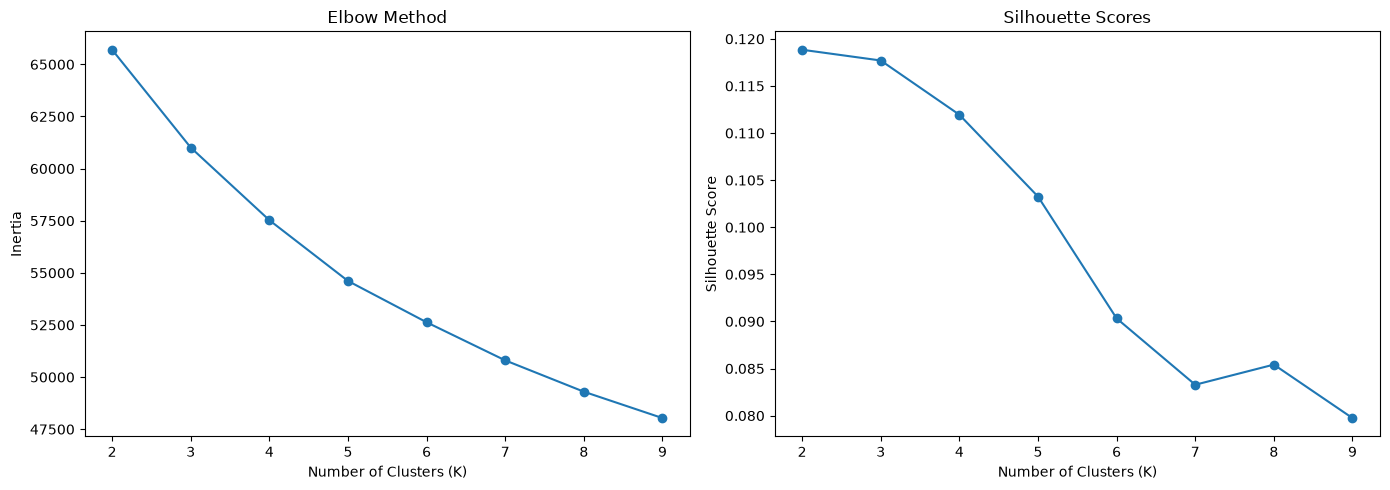

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# test different numbers of clusters
k_values = range(2, 10)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(
            X_cluster,
            cluster_labels,
            sample_size=2000,
            random_state=42
        )
    )

# plot the results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [25]:
# K = 2 has the highest silhouette score (0.118) and K = 3 is very similar with 0.1177.
# We will choose to fit at K = 3 despite K = 2 having a higher score since 3 clusters may provide more useful detail when profiling different lifestyle groups; however, the slightly lower silhouette scores indicate more overlap between clusters.

In [26]:
# fit K-Means using 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

clustered_sleep = sleep.copy()

# add cluster assignments
clustered_sleep["cluster"] = cluster_labels

# examine the number of observations in each cluster
print(clustered_sleep["cluster"].value_counts().sort_index())

cluster
0    3802
1    3401
2    1297
Name: count, dtype: int64


In [27]:
# compare average numerical features across clusters
cluster_summary = clustered_sleep.groupby("cluster")[
    numeric_features_cluster
].mean()

display(cluster_summary.round(2))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
cluster,,,,,,
0,34.38,60.02,54.83,0.00,14.45,35.62
1,34.52,59.25,55.38,1.00,15.06,35.82
2,33.87,57.00,55.51,0.44,135.90,35.63


In [28]:
# examine chronotype distribution within each cluster
display(
    pd.crosstab(
        clustered_sleep["cluster"],
        clustered_sleep["chronotype"],
        normalize="index"
    ).round(3) * 100
)

# examine occupation distribution within each cluster
display(
    pd.crosstab(
        clustered_sleep["cluster"],
        clustered_sleep["occupation_type"],
        normalize="index"
    ).round(3) * 100
)

chronotype,Intermediate,Morning Lark,Night Owl
cluster,,,
0,46.4,25.2,28.3
1,45.2,25.4,29.4
2,44.5,26.2,29.3


occupation_type,Corporate 9-to-5,Freelance / Creative,Healthcare / Shift Worker,Remote Tech,Student
cluster,,,,,
0,38.6,12.6,14.0,19.3,15.5
1,27.6,8.0,9.0,31.6,23.8
2,33.5,11.4,12.0,25.9,17.1


In [29]:
# compare clusters against sleep-debt severity
cluster_sleep_debt = pd.crosstab(
    clustered_sleep["cluster"],
    clustered_sleep["sleep_debt_category"],
    normalize="index"
) * 100

display(cluster_sleep_debt.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
cluster,,,,
0,22.09,53.05,16.28,8.57
1,24.90,52.98,17.11,5.00
2,24.44,49.58,14.34,11.64


In [30]:
# The K-Means results identified three groups with relatively balanced cluster sizes. 

# The numerical and categorical summaries showed some differences in lifestyle characteristics across clusters, although age and bedtime phone usage were relatively similar.

# The distribution of sleep-debt categories also differed across clusters. Cluster 2 had the highest proportion of Severe Sleep Debt (11.64%), while Cluster 1 had the lowest (5.00%).

# However, the low silhouette scores suggest that the clusters are not strongly separated. These results indicate that lifestyle characteristics may capture some differences in sleep-debt patterns, but the discovered groups are not clearly distinct.

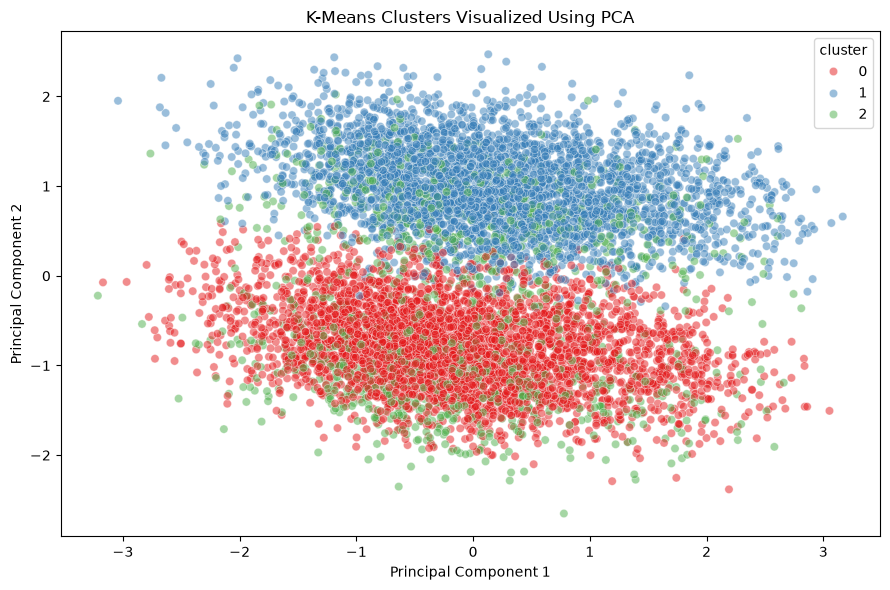

Explained variance: [0.1172266  0.11656228]
Total variance explained: 0.23378887871451615


In [31]:
from sklearn.decomposition import PCA

# reduce the transformed features to two dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

# create a dataframe for visualization
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": cluster_labels
})

# plot the clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set1",
    alpha=0.5
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

# examine how much variance the two components explain
print("Explained variance:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

In [32]:
# PCA reduced the 23 transformed features to two principal components for visualization. The first component explained 11.72% of the variance, and the second explained 11.66%, for a combined explained variance of 23.38%.

# The PCA visualization shows considerable overlap between the red and blue clusters, while the green cluster appears more spread out.

# There is no clear separation between all three groups in the two-dimensional projection. However, the first two principal components explain only 23.38% of the total variance, so the visualization may not capture all of the separation present in the original feature space.

Isolation Forest: detecting anonmolies

In [33]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

# identify anomalies
anomaly_predictions = isolation_forest.fit_predict(X_cluster)


sleep_with_anomalies = sleep.copy()

# add anomaly labels
sleep_with_anomalies["anomaly"] = anomaly_predictions

# count normal observations and anomalies
print(sleep_with_anomalies["anomaly"].value_counts())

anomaly
 1    8075
-1     425
Name: count, dtype: int64


In [34]:
contamination_values = [0.01, 0.05, 0.10]

anomaly_results = []

for contamination in contamination_values:
    model = IsolationForest(
        contamination=contamination,
        random_state=42
    )

    predictions = model.fit_predict(X_cluster)

    anomaly_count = (predictions == -1).sum()

    anomaly_results.append({
        "Contamination": contamination,
        "Anomaly Count": anomaly_count,
        "Anomaly Percentage": (anomaly_count / len(sleep)) * 100
    })

anomaly_summary = pd.DataFrame(anomaly_results)

display(anomaly_summary.round(2))

,Contamination,Anomaly Count,Anomaly Percentage
0,0.01,85,1.0
1,0.05,425,5.0
2,0.10,850,10.0


In [35]:
contamination_comparison = []

for contamination in contamination_values:
    model = IsolationForest(
        contamination=contamination,
        random_state=42
    )

    predictions = model.fit_predict(X_cluster)

    temp = sleep.copy()
    temp["anomaly"] = predictions

    anomaly_rows = temp[temp["anomaly"] == -1]

    contamination_comparison.append({
        "Contamination": contamination,
        "Anomaly Count": len(anomaly_rows),
        "Average Phone Usage": anomaly_rows["bedtime_phone_minutes"].mean(),
        "Average Caffeine": anomaly_rows["caffeine_post_5pm_mg"].mean(),
        "Severe Sleep Debt (%)": (
            anomaly_rows["sleep_debt_category"] == "Severe Sleep Debt"
        ).mean() * 100
    })

display(pd.DataFrame(contamination_comparison).round(2))

,Contamination,Anomaly Count,Average Phone Usage,Average Caffeine,Severe Sleep Debt (%)
0,0.01,85,68.96,57.81,16.47
1,0.05,425,69.20,72.44,16.94
2,0.10,850,69.01,70.95,15.88


In [36]:
# The contamination parameter controls the proportion of observations identified as anomalies. We compared settings of 1%, 5%, and 10%.

# The average phone usage and proportion of Severe Sleep Debt were relatively consistent across all three settings.

# We chose 5% as a reasonable middle setting for further exploration. However, this does not establish that exactly 5% of the observations are truly anomalous.

In [37]:
# separate normal observations and anomalies
anomalies = sleep_with_anomalies[
    sleep_with_anomalies["anomaly"] == -1
]

normal_observations = sleep_with_anomalies[
    sleep_with_anomalies["anomaly"] == 1
]

print("Number of anomalies:", len(anomalies))
print("Number of normal observations:", len(normal_observations))

# examine some detected anomalies
display(anomalies[cluster_features].head(10))

Number of anomalies: 425
Number of normal observations: 8075


,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
3,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49
69,63,Female,Healthcare / Shift Worker,Night Owl,165,YouTube,45,1,0,26
112,55,Non-Binary,Remote Tech,Intermediate,40,Streaming (Netflix/Hulu),67,0,0,69
120,45,Non-Binary,Corporate 9-to-5,Night Owl,54,YouTube,16,1,0,27
140,59,Male,Student,Morning Lark,29,Instagram / Reddit,55,0,221,48
156,39,Male,Healthcare / Shift Worker,Night Owl,25,News / Reading,58,0,203,27
168,19,Female,Healthcare / Shift Worker,Intermediate,42,Instagram / Reddit,98,0,196,42
235,41,Non-Binary,Student,Intermediate,130,YouTube,100,1,0,64
247,60,Female,Healthcare / Shift Worker,Night Owl,75,Streaming (Netflix/Hulu),68,1,51,46
248,59,Female,Healthcare / Shift Worker,Night Owl,67,Messaging / Chat,59,1,0,17


In [38]:
anomaly_comparison = sleep_with_anomalies.groupby("anomaly")[
    numeric_features_cluster
].mean()

anomaly_comparison.index = anomaly_comparison.index.map({
    1: "Normal",
    -1: "Anomaly"
})

display(anomaly_comparison.round(2))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
anomaly,,,,,,
Anomaly,40.30,69.20,56.21,0.50,72.44,37.63
Normal,34.04,58.73,55.10,0.47,31.16,35.60


In [39]:
anomaly_sleep_debt = pd.crosstab(
    sleep_with_anomalies["anomaly"],
    sleep_with_anomalies["sleep_debt_category"],
    normalize="index"
) * 100

anomaly_sleep_debt.index = anomaly_sleep_debt.index.map({
    1: "Normal",
    -1: "Anomaly"
})

display(anomaly_sleep_debt.round(2))

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
anomaly,,,,
Anomaly,20.24,47.53,15.29,16.94
Normal,23.75,52.76,16.37,7.12


In [40]:
# Isolation Forest identified 425 anomalies (5% of the dataset) using a contamination setting of 0.05.

# Compared with normal observations, anomalies had higher average bedtime phone usage (69.20 vs. 58.73 minutes), evening caffeine consumption (72.44 vs. 31.16 mg), and age (40.30 vs. 34.04).

# The most noticeable difference appeared in sleep-debt severity. Severe Sleep Debt represented 16.94% of anomalies, compared with 7.12% of normal observations.

# This suggests that unusual combinations of lifestyle and technology habits may be associated with greater sleep-debt severity. However, anomalies are not necessarily incorrect observations, so we will retain them rather than automatically removing them from the dataset.

Feature Engineering

According to the dataset description, physiological sleep measurements and next-day fatigue scores are calculated based on simulated lifestyle and technology habits. Since our goal is to predict sleep-debt severity using demographic and behavioral information, we focused on these input features when preparing our classification models.

We excluded physiological sleep measurements and next-day fatigue scores from our predictors because they may contain information closely related to the sleep-debt category. Including them could introduce target leakage and make model performance less representative of how well sleep-debt severity can be predicted using lifestyle and technology habits alone.

Binning:

In [41]:
sleep_fe = sleep.copy()

# bin age into groups
sleep_fe["age_group"] = pd.cut(
    sleep_fe["age"],
    bins=[17, 25, 35, 45, 65],
    labels=["18-25", "26-35", "36-45", "46-65"]
)

# categorize bedtime phone usage
sleep_fe["phone_use_level"] = pd.cut(
    sleep_fe["bedtime_phone_minutes"],
    bins=[-1, 30, 60, 90, float("inf")],
    labels=["0-30", "31-60", "61-90", "Over 90"]
)

# categorize evening caffeine consumption
sleep_fe["caffeine_level"] = pd.cut(
    sleep_fe["caffeine_post_5pm_mg"],
    bins=[-1, 0, 50, float("inf")],
    labels=["None", "1-50 mg", "Over 50 mg"]
)

In [42]:
# examine the distribution of the newly created features
for feature in ["age_group", "phone_use_level", "caffeine_level"]:
    print("\n", feature)
    display(sleep_fe[feature].value_counts().sort_index())


 age_group


age_group
18-25    2232
26-35    2863
36-45    1879
46-65    1526
Name: count, dtype: int64


 phone_use_level


phone_use_level
0-30       2051
31-60      3038
61-90      1866
Over 90    1545
Name: count, dtype: int64


 caffeine_level


caffeine_level
None          4950
1-50 mg       1278
Over 50 mg    2272
Name: count, dtype: int64

In [43]:
# compare engineered features with sleep debt categories
for feature in ["age_group", "phone_use_level", "caffeine_level"]:

    comparison = pd.crosstab(
        sleep_fe[feature],
        sleep_fe["sleep_debt_category"],
        normalize="index"
    ) * 100

    print("\nSleep Debt Distribution by", feature)
    display(comparison.round(2))


Sleep Debt Distribution by age_group


sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
age_group,,,,
18-25,22.80,52.11,15.95,9.14
26-35,23.40,53.41,16.07,7.13
36-45,25.12,52.00,15.97,6.92
46-65,23.13,51.97,17.76,7.14



Sleep Debt Distribution by phone_use_level


sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
phone_use_level,,,,
0-30,29.30,35.88,34.67,0.15
31-60,30.91,50.46,17.81,0.82
61-90,20.20,66.99,6.65,6.16
Over 90,5.63,61.04,0.71,32.62



Sleep Debt Distribution by caffeine_level


sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
caffeine_level,,,,
None,23.96,53.17,16.91,5.96
1-50 mg,22.54,53.68,15.81,7.98
Over 50 mg,23.33,50.35,15.32,11.00


In [44]:
# Binning Analysis

# Age groups showed relatively similar sleep-debt distributions. The percentage of Severe Sleep Debt ranged from 6.92% to 9.14%, suggesting that age group alone may not strongly influence sleep-debt severity.

# Phone usage showed the largest differences. Severe Sleep Debt increased from 0.15% among those using their phones for 0-30 minutes to 32.62% among those using their phones for over 90 minutes.

# Caffeine consumption also showed a gradual increase in Severe Sleep Debt, from 5.96% among individuals consuming no evening caffeine to 11.00% among those consuming over 50 mg.

One-hot Encoding:

In [45]:
# numerical features
numeric_features = [
    "age",
    "bedtime_phone_minutes",
    "screen_brightness_pct",
    "blue_light_filter_active",
    "caffeine_post_5pm_mg",
    "physical_activity_min"
]

# categorical features (includes features created by binning)
categorical_features = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app",
    "age_group",
    "phone_use_level",
    "caffeine_level"
]

# define predictors and target
X = sleep_fe[numeric_features + categorical_features]
y = sleep_fe["sleep_debt_category"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (8500, 13)
Target shape: (8500,)


In [46]:
# before encoding, we will split the data into training (80%) and testing (20%) to balance having enough observations for training while reserving enough data for evaluating model performance on unseen observations

from sklearn.model_selection import train_test_split

# split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (6800, 13)
Testing features: (1700, 13)
Training target: (6800,)
Testing target: (1700,)


In [47]:
# compare target distributions in training and testing sets
print("Training target distribution:")
display(y_train.value_counts(normalize=True).round(3) * 100)

print("Testing target distribution:")
display(y_test.value_counts(normalize=True).round(3) * 100)

Training target distribution:


sleep_debt_category
Moderate Debt        52.5
Mild Deficit         23.6
Optimal Recovery     16.3
Severe Sleep Debt     7.6
Name: proportion, dtype: float64

Testing target distribution:


sleep_debt_category
Moderate Debt        52.5
Mild Deficit         23.6
Optimal Recovery     16.3
Severe Sleep Debt     7.6
Name: proportion, dtype: float64

In [48]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# preprocess numerical and categorical features separately
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Modeling

We trained and tuned three classification algorithms to predict sleep debt category: K-Nearest Neighbors, Decision Tree, and Support Vector Machine. All models use the same preprocessing pipeline (standardized numeric features + one-hot encoded categorical features), the same 80/20 train/test split, and 5-fold stratified cross-validation scored by macro F1 so their results can be compared fairly.

## Support Vector Machine (SVM) 

An SVM finds the decision boundary that separates the classes with the widest possible margin. With a kernel (RBF, polynomial) it can learn non-linear boundaries. Because SVMs rely on distances and dot products, the standardized + one-hot encoded features from our `preprocessor` are required.

`SVC` handles our four classes using a one-vs-one scheme. Every model below is a `Pipeline` (preprocessor → SVC), so scaling/encoding is fit only on the training folds during cross-validation, avoiding data leakage.

**Evaluation metric:** since the target is imbalanced (Severe Sleep Debt is only 7.6%), we use **macro-averaged F1** as the main metric for tuning. Each class counts equally, so a model can't score well by just predicting "Moderate Debt". We also report accuracy and balanced accuracy.

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# ordinal order of the target classes (least to most sleep debt), used for all tables/plots
class_order = ["Optimal Recovery", "Mild Deficit", "Moderate Debt", "Severe Sleep Debt"]

# same 5-fold stratified split for every experiment so results are comparable
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "balanced_accuracy": "balanced_accuracy"}

def make_svm(**params):
    return Pipeline([("preprocess", preprocessor), ("svm", SVC(random_state=42, **params))])

def cv_summary(model, X_data=X_train, y_data=y_train):
    scores = cross_validate(model, X_data, y_data, cv=cv, scoring=scoring, n_jobs=-1)
    return {name: scores[f"test_{name}"].mean() for name in scoring}

### Step 1: Baselines

First we establish reference points: a majority-class dummy model (always predicts "Moderate Debt") and SVMs with default settings for each kernel.

In [50]:
baseline_models = {
    "Majority-class dummy": Pipeline([("preprocess", preprocessor),
                                      ("clf", DummyClassifier(strategy="most_frequent"))]),
    "SVM linear (default)": make_svm(kernel="linear"),
    "SVM RBF (default)": make_svm(kernel="rbf"),
    "SVM polynomial (default)": make_svm(kernel="poly"),
}

baseline_results = pd.DataFrame({name: cv_summary(model) for name, model in baseline_models.items()}).T
display(baseline_results.round(3))

,accuracy,f1_macro,balanced_accuracy
Majority-class dummy,0.525,0.172,0.250
SVM linear (default),0.711,0.675,0.661
SVM RBF (default),0.712,0.659,0.633
SVM polynomial (default),0.703,0.644,0.618


**Baseline results**

- The majority-class dummy always predicts "Moderate Debt", so its accuracy (0.525) just equals the share of Moderate Debt in the data. Its macro F1 (0.172) and balanced accuracy (0.250, i.e. 1 out of 4 classes) show it never predicts the other three categories. This is why accuracy alone is misleading for our imbalanced target.
- All three default SVMs clearly beat the baseline, reaching about 0.70–0.71 accuracy and 0.64–0.68 macro F1. So our lifestyle and technology features do contain real signal about sleep-debt severity.
- The kernels have nearly identical accuracy, but they differ more on macro F1 and balanced accuracy, the metrics that weigh the rare classes equally. The linear kernel did best (macro F1 0.675), followed by RBF (0.659) and polynomial (0.644). This suggests the classes may be close to linearly separable after one-hot encoding and scaling.
- These are untuned default settings, so next we tune C, gamma, degree, and class weighting to see if performance improves.

### Step 2: Hyperparameter tuning (GridSearchCV)

Hyperparameters searched:
- **kernel**: `linear`, `rbf`, `poly` = the shape of the decision boundary
- **C**: regularization strength. Small C = wider margin, more misclassifications allowed; large C = tighter fit to training data (risk of overfitting)
- **gamma** (RBF/poly): how far the influence of a single training point reaches. Large gamma = very local, wiggly boundaries
- **degree** (poly): polynomial degree
- **class_weight**: `None` vs `balanced`. `balanced` raises the penalty for misclassifying rare classes (Severe Sleep Debt), which addresses the class imbalance

The search is scored by 5-fold CV macro F1 on the training set only. The test set is not touched until the final evaluation.

In [51]:
param_grid = [
    {"svm__kernel": ["linear"],
     "svm__C": [0.01, 0.1, 1, 10],
     "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["rbf"],
     "svm__C": [0.1, 1, 10, 100],
     "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1],
     "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["poly"],
     "svm__C": [0.1, 1, 10],
     "svm__degree": [2, 3],
     "svm__gamma": ["scale"],
     "svm__class_weight": [None, "balanced"]},
]

svm_grid = GridSearchCV(
    make_svm(),
    param_grid,
    cv=cv,
    scoring=scoring,
    refit="f1_macro",          # choose the final model by macro F1
    n_jobs=-1,
    return_train_score=True
)
svm_grid.fit(X_train, y_train)

print("Best parameters:", svm_grid.best_params_)
print("Best CV macro F1:", round(svm_grid.best_score_, 3))

Best parameters: {'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Best CV macro F1: 0.675


In [52]:
# tidy table of all grid search results
grid_results = pd.DataFrame(svm_grid.cv_results_)
grid_results["kernel"] = grid_results["param_svm__kernel"]
grid_results["C"] = grid_results["param_svm__C"]
grid_results["gamma"] = grid_results["param_svm__gamma"].map(lambda g: "-" if pd.isna(g) else str(g))
grid_results["degree"] = grid_results["param_svm__degree"].map(lambda d: "-" if pd.isna(d) else str(int(d)))
grid_results["class_weight"] = grid_results["param_svm__class_weight"].map(lambda w: "None" if pd.isna(w) else str(w))

summary_cols = ["kernel", "C", "gamma", "degree", "class_weight",
                "mean_test_f1_macro", "mean_test_accuracy", "mean_test_balanced_accuracy",
                "mean_train_f1_macro"]

# top 10 configurations overall
display(grid_results.sort_values("mean_test_f1_macro", ascending=False)[summary_cols].head(10).round(3))

# best configuration for each kernel
best_per_kernel = (grid_results.sort_values("mean_test_f1_macro", ascending=False)
                   .groupby("kernel").head(1)[summary_cols])
display(best_per_kernel.round(3))

# effect of class balancing: best score for each kernel with and without class_weight="balanced"
display(grid_results.pivot_table(index="kernel", columns="class_weight",
                                 values=["mean_test_f1_macro", "mean_test_balanced_accuracy"],
                                 aggfunc="max").round(3))

,kernel,C,gamma,degree,class_weight,mean_test_f1_macro,mean_test_accuracy,mean_test_balanced_accuracy,mean_train_f1_macro
30,rbf,10.0,0.01,-,None,0.675,0.717,0.657,0.690
4,linear,1.0,-,-,None,0.675,0.711,0.661,0.679
6,linear,10.0,-,-,None,0.673,0.710,0.658,0.679
39,rbf,100.0,0.001,-,None,0.672,0.710,0.656,0.680
2,linear,0.1,-,-,None,0.670,0.711,0.652,0.675
40,rbf,100.0,0.01,-,None,0.664,0.710,0.650,0.747
56,poly,10.0,scale,2,None,0.663,0.710,0.649,0.746
52,poly,1.0,scale,2,None,0.662,0.711,0.638,0.693
18,rbf,1.0,scale,-,None,0.659,0.712,0.633,0.727
21,rbf,1.0,0.1,-,None,0.656,0.710,0.631,0.741


,kernel,C,gamma,degree,class_weight,mean_test_f1_macro,mean_test_accuracy,mean_test_balanced_accuracy,mean_train_f1_macro
30,rbf,10.0,0.01,-,None,0.675,0.717,0.657,0.690
4,linear,1.0,-,-,None,0.675,0.711,0.661,0.679
56,poly,10.0,scale,2,None,0.663,0.710,0.649,0.746


mean_test_balanced_accuracy          mean_test_f1_macro         
class_weight                        None balanced               None balanced
kernel                                                                       
linear                             0.661    0.703              0.675    0.653
poly                               0.649    0.694              0.663    0.646
rbf                                0.657    0.703              0.675    0.649

**Grid search results**

- **Best overall:** the RBF kernel with C = 10 and gamma = 0.01 had the highest CV macro F1 (0.675) and accuracy (0.717), although the linear kernel with C = 1 performed nearly identically. This suggests the non-linear decision boundary gives only a marginal improvement over a linear model.
- **Linear is nearly as good:** the best linear kernel (C = 1) tied on macro F1 (0.675) and actually had slightly higher balanced accuracy (0.661 vs 0.657). Linear models fill 3 of the top 5 spots. That tells us the classes are close to linearly separable after scaling and one-hot encoding, so the non-linear kernel adds very little.
- **Polynomial was weakest:** its best setting (degree 2, C = 10) reached 0.663 macro F1.
- **Accuracy barely changes:** all top 10 configurations fall between 0.710 and 0.717 accuracy, but macro F1 ranges from 0.656 to 0.675. The tuning mainly affects how well the rare classes are predicted, which is why we tuned on macro F1.
- **Train vs. validation gap:** the best RBF model has a small gap (train 0.690 vs. validation 0.675), so it isn't overfitting. In contrast, RBF with C = 100 / gamma = 0.01 and polynomial with C = 10 reach about 0.75 on training but only about 0.66 on validation, a sign of overfitting.
- **Class balancing trade-off:** none of the top 10 configurations used class balancing. `class_weight='balanced'` raised balanced accuracy for every kernel (e.g. 0.703 vs 0.657 for RBF) because it catches more of the rare classes. However, it lowered macro F1 (e.g. 0.649 vs 0.675) because precision fell. Since we tuned on macro F1, the unweighted model was selected.

### Step 3: Visualizing the tuning results

The heatmaps show CV macro F1 for each (C, gamma) pair of the RBF kernel, with and without class balancing. The line plot compares training vs. validation F1 as C grows, to check for overfitting.

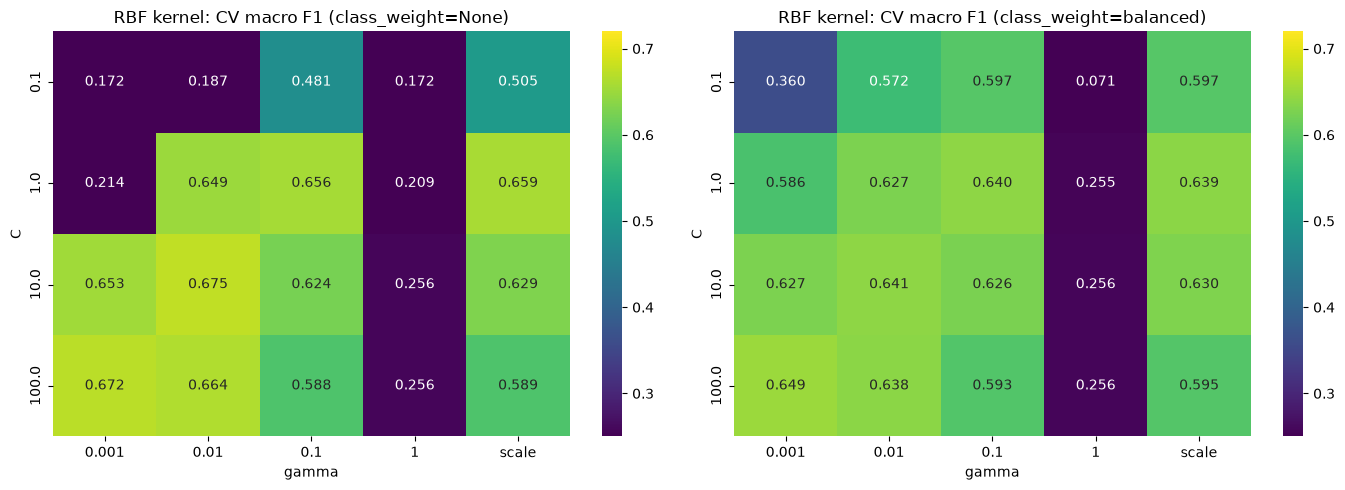

In [53]:
rbf_results = grid_results[grid_results["kernel"] == "rbf"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cw in zip(axes, ["None", "balanced"]):
    pivot = (rbf_results[rbf_results["class_weight"] == cw]
             .pivot_table(index="C", columns="gamma", values="mean_test_f1_macro"))
    gamma_order = sorted([g for g in pivot.columns if g != "scale"], key=float) + ["scale"]
    pivot = pivot[gamma_order]
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", ax=ax, vmin=0.25, vmax=0.72)
    ax.set_title(f"RBF kernel: CV macro F1 (class_weight={cw})")
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
plt.tight_layout()
plt.show()

**RBF heatmap results**

- **gamma has the biggest effect.** With gamma = 1, macro F1 collapses to about 0.21–0.26 for every value of C (and as low as 0.07 with balancing). Each training point only influences a tiny area around itself, so the model memorizes the training data and fails on new data.
- **C and gamma work together.** Small gammas (0.001 and 0.01) need a larger C to perform well. With C = 0.1, gamma = 0.001 only reaches 0.172 (the same as always predicting "Moderate Debt"), but with C = 100 it reaches 0.672. Larger gammas (0.1 and 'scale') do best around C = 1 and get worse as C increases.
- **Best region:** the highest score is **C = 10, gamma = 0.01 (0.675)**, with C = 100 / gamma = 0.001 (0.672) close behind. This is a moderately smooth decision boundary.
- **Class balancing:** the right heatmap is lower almost everywhere (best 0.649). Balancing makes the model predict the rare classes more often, but it loses precision, which lowers macro F1. It does help at very low C, where the unbalanced model just predicts the majority class.

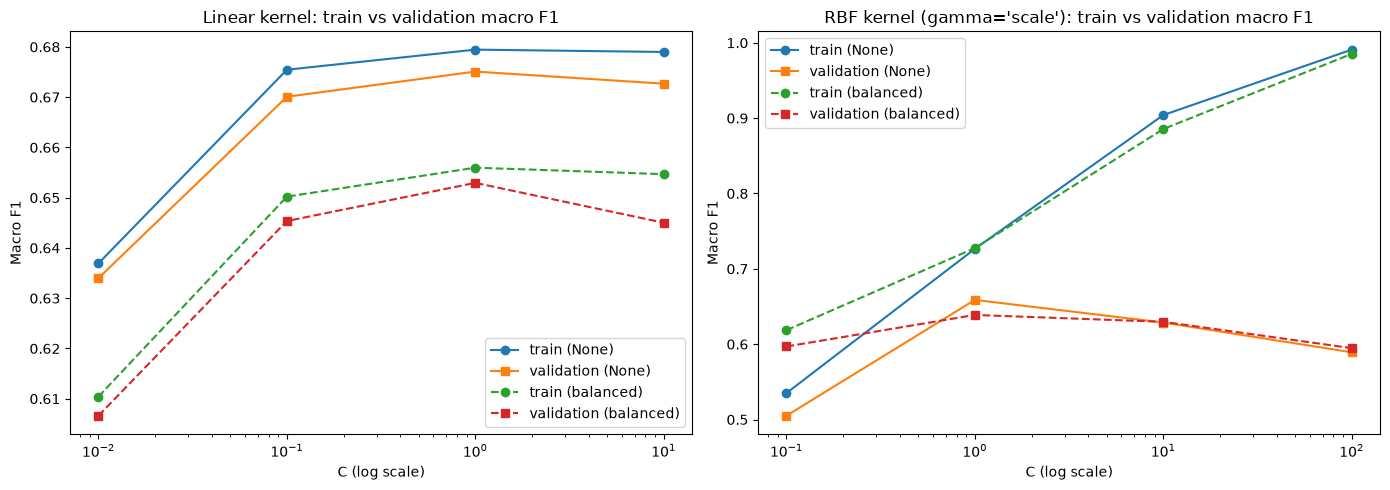

In [54]:
# training vs validation macro F1 as C changes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

linear_res = grid_results[grid_results["kernel"] == "linear"]
for cw, style in [("None", "-"), ("balanced", "--")]:
    sub = linear_res[linear_res["class_weight"] == cw].sort_values("C")
    axes[0].plot(sub["C"], sub["mean_train_f1_macro"], marker="o", linestyle=style, label=f"train ({cw})")
    axes[0].plot(sub["C"], sub["mean_test_f1_macro"], marker="s", linestyle=style, label=f"validation ({cw})")
axes[0].set_xscale("log")
axes[0].set_title("Linear kernel: train vs validation macro F1")

rbf_scale = rbf_results[rbf_results["gamma"] == "scale"]
for cw, style in [("None", "-"), ("balanced", "--")]:
    sub = rbf_scale[rbf_scale["class_weight"] == cw].sort_values("C")
    axes[1].plot(sub["C"], sub["mean_train_f1_macro"], marker="o", linestyle=style, label=f"train ({cw})")
    axes[1].plot(sub["C"], sub["mean_test_f1_macro"], marker="s", linestyle=style, label=f"validation ({cw})")
axes[1].set_xscale("log")
axes[1].set_title("RBF kernel (gamma='scale'): train vs validation macro F1")

for ax in axes:
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("Macro F1")
    ax.legend()
plt.tight_layout()
plt.show()

**Train vs. validation results**

- **Linear kernel:** training and validation F1 stay within about 0.01 of each other at every C, so the linear model does not overfit. Performance levels off after C = 0.1, peaking at C = 1.
- **RBF kernel (gamma = 'scale'):** as C increases, training F1 rises steeply to 0.99 at C = 100 while validation F1 drops from 0.66 to 0.59. This is clear overfitting: a large C lets the model bend around individual training points.
- Overall, the best settings sit in a middle ground: enough flexibility to fit the data without memorizing the training set. This matches the grid search choosing C = 10 with a small gamma (0.01) rather than the most flexible settings.

### Step 4: Feature engineering & cleaning checks

Using the tuned hyperparameters, we test two decisions from the data-preparation stage with the SVM:
1. **Binned features**: does adding `age_group`, `phone_use_level`, and `caffeine_level` help, or are the raw numeric columns enough?
2. **Anomalies**: does removing Isolation Forest anomalies from the training data help? To keep the test set untouched, this is checked with 5-fold CV on the training set. In each fold, the Isolation Forest is fit on the training portion only, the anomalies are removed from that portion, and the model is scored on the full validation fold.

In [55]:
best_svm_params = {k.replace("svm__", ""): v for k, v in svm_grid.best_params_.items()}

# 1) with vs without binned features (5-fold CV on training set)
binned_features = ["age_group", "phone_use_level", "caffeine_level"]
categorical_no_bins = [c for c in categorical_features if c not in binned_features]

preprocessor_no_bins = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_no_bins)
])
svm_no_bins = Pipeline([("preprocess", preprocessor_no_bins),
                        ("svm", SVC(random_state=42, **best_svm_params))])

bin_comparison = pd.DataFrame({
    "With binned features": cv_summary(make_svm(**best_svm_params)),
    "Without binned features": cv_summary(svm_no_bins, X_train[numeric_features + categorical_no_bins]),
}).T
display(bin_comparison.round(3))

,accuracy,f1_macro,balanced_accuracy
With binned features,0.717,0.675,0.657
Without binned features,0.719,0.670,0.647


In [56]:
# 2) keep vs remove Isolation Forest anomalies, using CV on the training set only
from sklearn.ensemble import IsolationForest
from sklearn.metrics import recall_score

# same lifestyle features used for the original Isolation Forest
anomaly_inputs = ["age", "gender", "occupation_type", "chronotype", "bedtime_phone_minutes",
                  "primary_bedtime_app", "screen_brightness_pct", "blue_light_filter_active",
                  "caffeine_post_5pm_mg", "physical_activity_min"]
anomaly_num = [c for c in anomaly_inputs if c in numeric_features]
anomaly_cat = [c for c in anomaly_inputs if c not in numeric_features]

fold_results = {"Keep anomalies": [], "Remove anomalies": []}
removed_counts = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    # fit Isolation Forest on the training fold only
    anomaly_pipe = Pipeline([
        ("prep", ColumnTransformer([("num", StandardScaler(), anomaly_num),
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), anomaly_cat)])),
        ("iso", IsolationForest(contamination=0.05, random_state=42))
    ])
    is_normal = anomaly_pipe.fit_predict(X_tr[anomaly_inputs]) == 1
    removed_counts.append((~is_normal).sum())

    for name, mask in [("Keep anomalies", np.ones(len(X_tr), dtype=bool)),
                       ("Remove anomalies", is_normal)]:
        model = make_svm(**best_svm_params).fit(X_tr[mask], y_tr[mask])
        pred = model.predict(X_val)      # always validate on the full fold
        fold_results[name].append({
            "accuracy": accuracy_score(y_val, pred),
            "f1_macro": f1_score(y_val, pred, average="macro"),
            "balanced_accuracy": balanced_accuracy_score(y_val, pred),
            "severe_recall": recall_score(y_val, pred, labels=["Severe Sleep Debt"], average="macro"),
        })

print("Anomalies removed per training fold:", removed_counts)
anomaly_check = pd.DataFrame({name: pd.DataFrame(rows).mean() for name, rows in fold_results.items()}).T
display(anomaly_check.round(3))

Anomalies removed per training fold: [np.int64(272), np.int64(272), np.int64(272), np.int64(272), np.int64(272)]


,accuracy,f1_macro,balanced_accuracy,severe_recall
Keep anomalies,0.717,0.675,0.657,0.62
Remove anomalies,0.717,0.674,0.655,0.61


**Feature engineering & cleaning checks**

- **Binned features:** with the binned columns, CV macro F1 was 0.675; without them it was 0.670 (balanced accuracy 0.657 vs 0.647). The improvement is small but consistent, so we kept the bins. The gain is modest because an RBF SVM can already learn thresholds on the raw numeric columns. The bins mostly make the phone-usage cutoffs explicit.
- **Anomalies:** removing Isolation Forest anomalies (272 per training fold, fit on training data only) made almost no difference in cross-validation (macro F1 0.674 vs 0.675; Severe recall 0.61 vs 0.62). This supports the earlier decision to keep anomalies. They appear to be unusual but valid observations rather than errors, and keeping them slightly helps the model recognize Severe Sleep Debt.

### Step 5: Final evaluation on the test set

The best model from the grid search (already refit on the full training set) is evaluated once on the held-out 20% test set.

In [57]:
best_svm = svm_grid.best_estimator_
y_pred_svm = best_svm.predict(X_test)

svm_test_results = {
    "Model": "SVM",
    "Best params": svm_grid.best_params_,
    "CV macro F1": svm_grid.best_score_,
    "Test accuracy": accuracy_score(y_test, y_pred_svm),
    "Test macro F1": f1_score(y_test, y_pred_svm, average="macro"),
    "Test weighted F1": f1_score(y_test, y_pred_svm, average="weighted"),
    "Test balanced accuracy": balanced_accuracy_score(y_test, y_pred_svm),
}
for k, v in svm_test_results.items():
    print(f"{k}: {round(v, 3) if isinstance(v, float) else v}")

print()
print(classification_report(y_test, y_pred_svm, labels=class_order, digits=3))

Model: SVM
Best params: {'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
CV macro F1: 0.675
Test accuracy: 0.734
Test macro F1: 0.698
Test weighted F1: 0.739
Test balanced accuracy: 0.68

                   precision    recall  f1-score   support

 Optimal Recovery      0.719     0.599     0.654       277
     Mild Deficit      0.525     0.676     0.591       401
    Moderate Debt      0.854     0.817     0.835       893
Severe Sleep Debt      0.827     0.628     0.714       129

         accuracy                          0.734      1700
        macro avg      0.731     0.680     0.698      1700
     weighted avg      0.752     0.734     0.739      1700



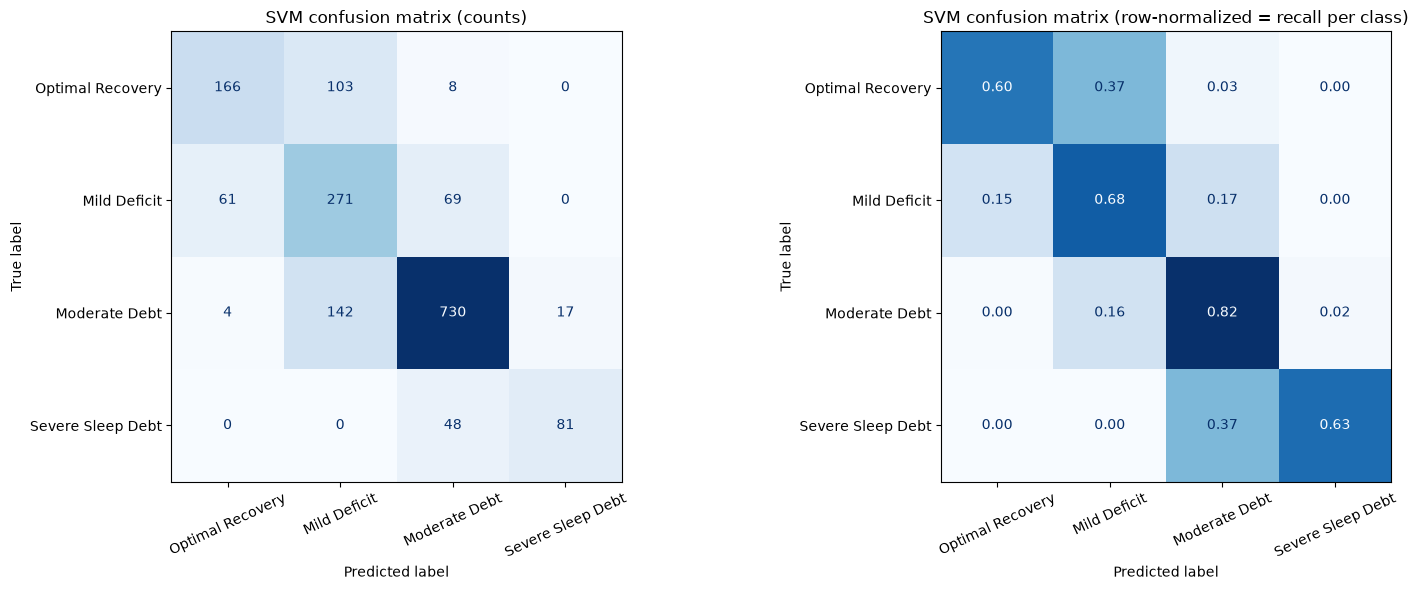

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, labels=class_order, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("SVM confusion matrix (counts)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, labels=class_order, normalize="true", values_format=".2f",
    ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("SVM confusion matrix (row-normalized = recall per class)")

for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

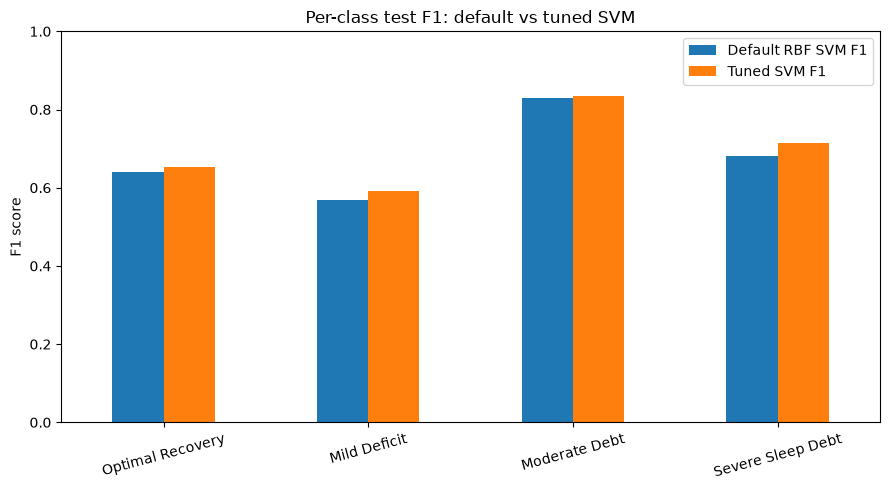

,Default RBF SVM F1,Tuned SVM F1
Optimal Recovery,0.641,0.654
Mild Deficit,0.568,0.591
Moderate Debt,0.829,0.835
Severe Sleep Debt,0.682,0.714


In [59]:
# compare the tuned model against the default RBF SVM on the test set
default_svm = make_svm(kernel="rbf").fit(X_train, y_train)
y_pred_default = default_svm.predict(X_test)

per_class = pd.DataFrame({
    "Default RBF SVM F1": f1_score(y_test, y_pred_default, labels=class_order, average=None),
    "Tuned SVM F1": f1_score(y_test, y_pred_svm, labels=class_order, average=None),
}, index=class_order)

per_class.plot(kind="bar", figsize=(9, 5))
plt.title("Per-class test F1: default vs tuned SVM")
plt.ylabel("F1 score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()
display(per_class.round(3))

**Test set results**

- The tuned SVM reached **accuracy 0.734, macro F1 0.698, and balanced accuracy 0.680** on the held-out test set. The test macro F1 is close to the cross-validation score (0.675), which suggests the model performs consistently on the validation folds and on unseen data, with no obvious sign of overfitting.
- **Moderate Debt** is predicted best (F1 0.835), since it is the largest class. **Severe Sleep Debt** comes next (F1 0.714): when the model predicts Severe it is usually right (precision 0.827), but it only catches 63% of the actual Severe cases (recall 0.628).
- **Mild Deficit** is the hardest class (F1 0.591, precision 0.525), because it sits between Optimal Recovery and Moderate Debt and gets confused with both.
- The confusion matrix shows the main mistakes are between neighboring categories: 37% of Optimal Recovery cases are predicted as Mild Deficit, and 37% of Severe cases are predicted as Moderate Debt. No Optimal case was ever predicted as Severe, or vice versa.
- Compared with the default RBF SVM, tuning improved F1 for **every class**. The biggest gain was for Severe Sleep Debt (0.682 → 0.714).

### Step 6: Error analysis

Our target is ordinal (Optimal < Mild < Moderate < Severe), so a mistake between neighboring categories is much less serious than confusing Optimal Recovery with Severe Sleep Debt. We measure how far off each wrong prediction is, then look at what the misclassified people have in common.

In [65]:
rank = {label: i for i, label in enumerate(class_order)}
distance = np.abs(y_test.map(rank).values - pd.Series(y_pred_svm).map(rank).values)

error_distance = pd.Series(distance).value_counts().sort_index()
error_distance.index = error_distance.index.map({0: "Correct", 1: "Off by 1 category",
                                                 2: "Off by 2 categories", 3: "Off by 3 categories"})
display(pd.DataFrame({"Count": error_distance,
                      "Percent of test set": (error_distance / len(y_test) * 100).round(2)}))

# direction of mistakes: over- or under-estimating sleep debt
signed = pd.Series(y_pred_svm).map(rank).values - y_test.map(rank).values
print("Over-predicted severity: ", (signed > 0).sum())
print("Under-predicted severity:", (signed < 0).sum())

,Count,Percent of test set
Correct,1248,73.41
Off by 1 category,440,25.88
Off by 2 categories,12,0.71


Over-predicted severity:  197
Under-predicted severity: 255


In [61]:
# compare correctly vs incorrectly classified test observations
test_analysis = X_test.copy()
test_analysis["actual"] = y_test.values
test_analysis["predicted"] = y_pred_svm
test_analysis["correct"] = test_analysis["actual"] == test_analysis["predicted"]

display(test_analysis.groupby("correct")[numeric_features].mean().round(2))

# error rate by chronotype and occupation
display((1 - test_analysis.groupby("chronotype")["correct"].mean()).rename("error rate").round(3))
display((1 - test_analysis.groupby("occupation_type")["correct"].mean()).rename("error rate").round(3))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
correct,,,,,,
False,36.22,53.79,56.71,0.48,35.86,35.01
True,33.91,61.56,54.97,0.47,33.56,35.61


chronotype
Intermediate    0.331
Morning Lark    0.321
Night Owl       0.125
Name: error rate, dtype: float64

occupation_type
Corporate 9-to-5             0.278
Freelance / Creative         0.263
Healthcare / Shift Worker    0.155
Remote Tech                  0.286
Student                      0.282
Name: error rate, dtype: float64

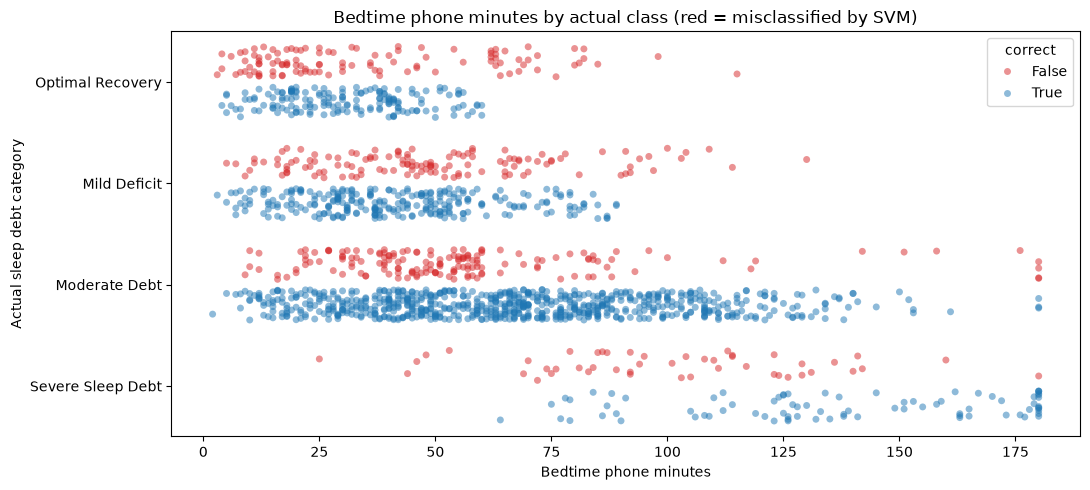

In [62]:
# where do the classes overlap? bedtime phone minutes is the strongest numeric predictor,
# so plot its distribution per actual class, marking correct vs incorrect predictions
plt.figure(figsize=(11, 5))
sns.stripplot(data=test_analysis, x="bedtime_phone_minutes", y="actual", hue="correct",
              order=class_order, alpha=0.5, jitter=0.3, dodge=True,
              palette={True: "tab:blue", False: "tab:red"})
plt.title("Bedtime phone minutes by actual class (red = misclassified by SVM)")
plt.xlabel("Bedtime phone minutes")
plt.ylabel("Actual sleep debt category")
plt.tight_layout()
plt.show()

**Error analysis**

- **Almost all errors are between neighboring categories.** 73.4% of test predictions were correct, 25.9% were off by one category, only 0.7% (12 people) were off by two, and none were off by three. The model never confused Optimal Recovery with Severe Sleep Debt.
- **Main confusions:** 37% of Optimal Recovery cases were predicted as Mild Deficit, and 37% of Severe Sleep Debt cases were predicted as Moderate Debt. Mild Deficit has the lowest precision (0.525) because it sits between Optimal and Moderate and absorbs errors from both sides.
- The model **under-predicts severity slightly more often than it over-predicts** (255 vs 197 errors). This matters because a missed Severe case is arguably the more costly mistake.
- **Who is misclassified?** Misclassified people used their phones less on average (53.8 vs 61.6 minutes) and were slightly older. In the strip plot, the classes overlap heavily between roughly 0 and 90 phone minutes, and most errors fall in that range. Severe cases below about 100 minutes and Optimal cases above about 60 minutes are usually missed.
- **Night Owls (12.5% error rate) and Healthcare/Shift Workers (15.5%) are much easier to classify** than Intermediate and Morning Lark chronotypes (~32–33%) and other occupations (~26–29%). Those groups are heavily concentrated in the Moderate/Severe categories, so the model has an easier job with them.

### Step 7: Which features does the SVM rely on?

RBF/polynomial SVMs don't provide feature importances directly, so we use **permutation importance**: shuffle one original column at a time in the test set and measure how much macro F1 drops. A bigger drop means the model depends more on that feature.

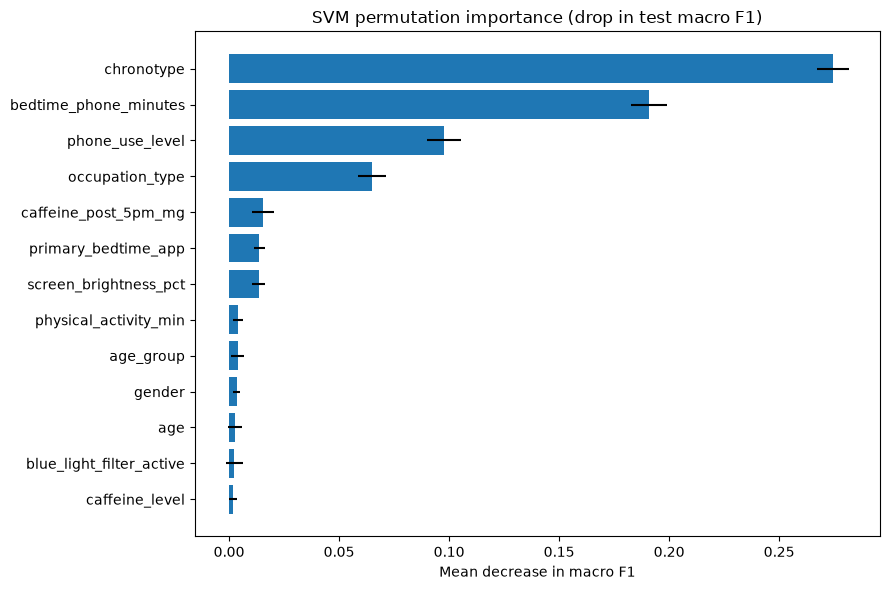

,feature,importance_mean,importance_std
8,chronotype,0.2745,0.0072
1,bedtime_phone_minutes,0.1908,0.0082
11,phone_use_level,0.0977,0.0076
7,occupation_type,0.0649,0.0064
4,caffeine_post_5pm_mg,0.0153,0.0050
9,primary_bedtime_app,0.0137,0.0025
2,screen_brightness_pct,0.0134,0.0030
5,physical_activity_min,0.0042,0.0023
10,age_group,0.0039,0.0029
6,gender,0.0035,0.0015


In [63]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_svm, X_test, y_test, scoring="f1_macro",
                              n_repeats=10, random_state=42, n_jobs=-1)

perm_importance = (pd.DataFrame({"feature": X_test.columns,
                                 "importance_mean": perm.importances_mean,
                                 "importance_std": perm.importances_std})
                   .sort_values("importance_mean", ascending=True))

plt.figure(figsize=(9, 6))
plt.barh(perm_importance["feature"], perm_importance["importance_mean"],
         xerr=perm_importance["importance_std"], color="tab:blue")
plt.title("SVM permutation importance (drop in test macro F1)")
plt.xlabel("Mean decrease in macro F1")
plt.tight_layout()
plt.show()

display(perm_importance.sort_values("importance_mean", ascending=False).round(4))

**Feature importance**

- **Chronotype** is by far the most important feature: shuffling it lowers test macro F1 by 0.27. Next are **bedtime phone minutes** (0.19), the binned **phone use level** (0.10), and **occupation type** (0.065).
- Caffeine, primary bedtime app, and screen brightness have small effects (about 0.013–0.015). Age, gender, blue-light filter, physical activity, and the caffeine/age bins contribute almost nothing.
- These results match the exploration section: chronotype, phone usage, and the shift-worker occupation showed the clearest differences between sleep-debt categories, while age and app type barely differed.
- Caveat: `bedtime_phone_minutes` and `phone_use_level` carry overlapping information. When one is shuffled the model can partly fall back on the other, so the combined importance of phone usage is likely higher than either value alone.
- Permutation importance shows which features the *model* relies on for its predictions. It does not show that these features *cause* sleep debt.

### SVM summary

In [64]:
display(pd.DataFrame([svm_test_results]).drop(columns="Best params").round(3))

,Model,CV macro F1,Test accuracy,Test macro F1,Test weighted F1,Test balanced accuracy
0,SVM,0.675,0.734,0.698,0.739,0.68


**SVM takeaways**

- Final model: **RBF SVM, C = 10, gamma = 0.01, no class weighting**. On the test set it reached **accuracy 0.734, macro F1 0.698, and balanced accuracy 0.680**, compared with 0.525 / 0.172 / 0.250 for the majority baseline on the same test set. The test score is close to the CV score (0.675), with no obvious sign of overfitting.
- Tuning improved test F1 for every class over the default RBF SVM, with the largest gain for Severe Sleep Debt (0.682 → 0.714).
- Performance seems to level off around 0.70 macro F1 for every kernel and setting we tried. This suggests the limit comes from the features rather than the algorithm: we intentionally excluded the physiological sleep measurements to avoid target leakage, so some of the variation in sleep debt cannot be predicted from lifestyle habits alone.